In [4]:
import pandas as pd

# 1. Load the dataset
df = pd.read_excel('../../03_data_raw/exploration_inputs/17_04_2026_ERM.xlsx')

# 2. Filter for the 2005-2016 timeframe
df['d_date_announcement'] = pd.to_datetime(df['d_date_announcement'], format='%Y-%m-%d', errors='coerce')
df['year'] = df['d_date_announcement'].dt.year
df_period = df[(df['year'] >= 2005) & (df['year'] <= 2016)].copy()

# 3. Filter for the Automotive Industry (NACE 29: Manufacture of motor vehicles)
df_auto = df_period[df_period['NACE_level_3'].astype(str).str.contains('^29', regex=True, na=False) | 
                    df_period['NACE_level_4'].astype(str).str.contains('^29', regex=True, na=False)].copy()

# Consolidate actual job loss numbers across different columns
df_auto['Job_Loss'] = df_auto[['Planned job red max', 'Planned job red min', 'Direct dimissals']].max(axis=1)

# -------------------------------------------------------------
# Replicating FIGURE 7: Plant Closures and Relocations
# -------------------------------------------------------------
# Isolate event types that represent closures or shifting operations
fig7_types = ['Closure', 'Relocation', 'Offshoring/Delocalisation']
df_fig7 = df_auto[df_auto['_kf_Type'].isin(fig7_types)]

# Group by country to get the total number of events and total jobs lost
fig7_summary = df_fig7.groupby('Country').agg(
    Number_of_closures_and_relocations=('_kf_Type', 'count'),
    Jobs_lost=('Job_Loss', 'sum')
).sort_values(by='Jobs_lost', ascending=False).head(15)

print("--- FIGURE 7: Top Countries for Closures and Relocations (2005-2016) ---")
print(fig7_summary)

# -------------------------------------------------------------
# Replicating FIGURE 8: New Factories
# -------------------------------------------------------------
# Start with general business expansions
df_exp = df_auto[df_auto['_kf_Type'] == 'Business expansion'].copy()

# Since ERM groups "expansions" and "new builds" together, we use NLP string matching
# to detect if the description explicitly mentions a brand new factory, plant, or facility.
keywords = ['new factory', 'new plant', 'new facility', 'opens', 'opened', 'new site', 'building a new', 'construct']
pattern = '|'.join(keywords)
df_exp['is_new_factory'] = df_exp['Description'].astype(str).str.lower().str.contains(pattern, regex=True)

# Filter down to just the newly identified factories
df_new_factories = df_exp[df_exp['is_new_factory'] == True]

# Group by country to get the total new factories and jobs created
fig8_summary = df_new_factories.groupby('Country').agg(
    Number_of_new_factories=('_kf_Type', 'count'),
    Jobs_created=('planned job creation', 'sum')
).sort_values(by='Jobs_created', ascending=False).head(15)

print("\n--- FIGURE 8: Top Countries for New Factories (2005-2016) ---")
print(fig8_summary)

--- FIGURE 7: Top Countries for Closures and Relocations (2005-2016) ---
                Number_of_closures_and_relocations  Jobs_lost
Country                                                      
United Kingdom                                  39    20473.0
Belgium                                         13    12108.0
France                                          40    10585.0
Spain                                           26     8980.0
Germany                                         24     7766.0
Portugal                                        14     7563.0
Italy                                           20     7181.0
Czechia                                         14     6159.0
Poland                                           6     4090.0
Sweden                                          13     3722.0
Slovakia                                         6     3468.0
Austria                                          5     1465.0
Ireland                                          5      902

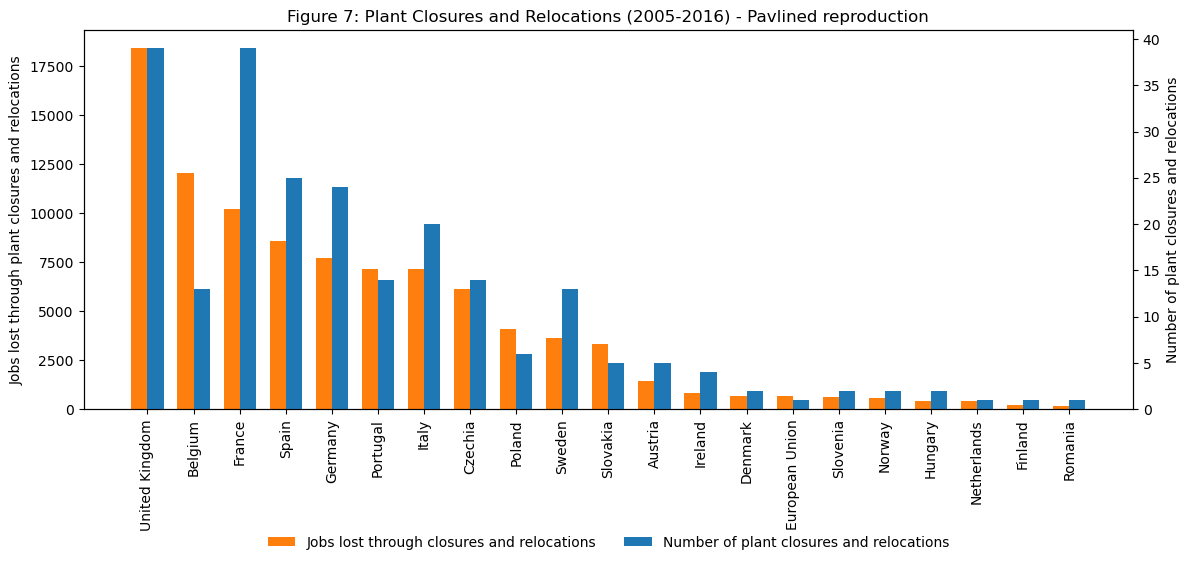

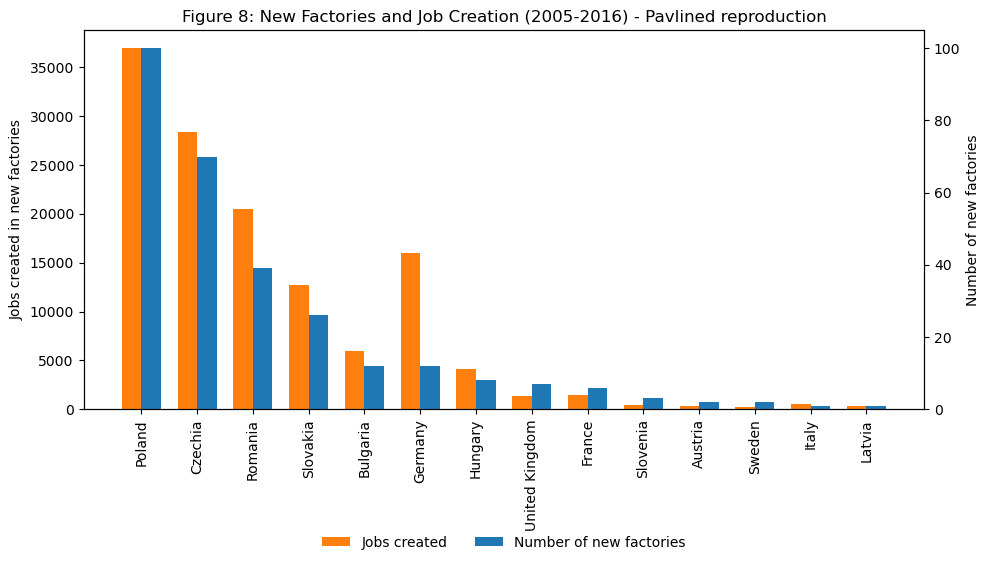

In [30]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# 1. Load the dataset
df = pd.read_excel("../../03_data_raw/exploration_inputs/17_04_2026_ERM.xlsx")

# 2. Filter for the 2005-2016 period
df['d_date_announcement'] = pd.to_datetime(df['d_date_announcement'], format='%Y-%m-%d', errors='coerce')
df['year'] = df['d_date_announcement'].dt.year
df_period = df[(df['year'] >= 2005) & (df['year'] <= 2016)].copy()

# 3. Filter for Automotive Industry (NACE 29)
df_auto = df_period[df_period['NACE_level_3'].astype(str).str.contains('^29', regex=True, na=False) | 
                    df_period['NACE_level_4'].astype(str).str.contains('^29', regex=True, na=False)].copy()

# -------------------------------------------------------------
# Apply the Author's Methodology Rules for Job Losses
# -------------------------------------------------------------
# Rule 1: Average the minimum and maximum ranges
df_auto['Job_Loss_Avg'] = df_auto[['Planned job red min', 'Planned job red max']].mean(axis=1)

# If ranges aren't provided, fall back to explicit direct dismissals
df_auto['Job_Loss_Avg'] = df_auto['Job_Loss_Avg'].fillna(df_auto['Direct dimissals'])

# Filter for Figure 7 Types
fig7_types = ['Closure', 'Relocation', 'Offshoring/Delocalisation']
df_fig7 = df_auto[df_auto['_kf_Type'].isin(fig7_types)].copy()

# Rule 2: Filter out minor events (must be >= 100 jobs impacted)
df_fig7 = df_fig7[df_fig7['Job_Loss_Avg'] >= 100]

fig7_summary = df_fig7.groupby('Country').agg(
    Number_of_closures_and_relocations=('_kf_Type', 'count'),
    Jobs_lost=('Job_Loss_Avg', 'sum')
).sort_values(by='Jobs_lost', ascending=False).head(22)

# -------------------------------------------------------------
# Apply the Author's Methodology Rules for Job Creations
# -------------------------------------------------------------
df_exp = df_auto[df_auto['_kf_Type'] == 'Business expansion'].copy()

# Rule 2: Filter out minor events (must be >= 100 jobs created)
df_exp = df_exp[df_exp['planned job creation'] >= 100]

# Rule 3: Detect explicitly "New" factories from the text descriptions
keywords = ['new factory', 'new plant', 'new facility', 'opens', 'opened', 'new site', 'building a new', 'construct']
pattern = '|'.join(keywords)
df_exp['is_new_factory'] = df_exp['Description'].astype(str).str.lower().str.contains(pattern, regex=True)
df_new_factories = df_exp[df_exp['is_new_factory'] == True]

fig8_summary = df_new_factories.groupby('Country').agg(
    Number_of_new_factories=('_kf_Type', 'count'),
    Jobs_created=('planned job creation', 'sum')
).sort_values(by='Number_of_new_factories', ascending=False) \
 .query("Country != 'World'") \
 .head(14)

# -------------------------------------------------------------
# PLOTTING FIGURE 7
# -------------------------------------------------------------
fig, ax1 = plt.subplots(figsize=(12, 6))
ax2 = ax1.twinx()
x = np.arange(len(fig7_summary))
width = 0.35

bars1 = ax1.bar(x - width/2, fig7_summary['Jobs_lost'], width, label='Jobs lost through closures and relocations', color='tab:orange')
bars2 = ax2.bar(x + width/2, fig7_summary['Number_of_closures_and_relocations'], width, label='Number of plant closures and relocations', color='tab:blue')

ax1.set_ylabel('Jobs lost through plant closures and relocations')
ax2.set_ylabel('Number of plant closures and relocations')
ax1.set_xticks(x)
ax1.set_xticklabels(fig7_summary.index, rotation=90)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper center', bbox_to_anchor=(0.5, -0.3), ncol=2, frameon=False)

plt.title("Figure 7: Plant Closures and Relocations (2005-2016) - Pavlined reproduction")
plt.tight_layout()
plt.savefig("figure_7_adjusted.png", bbox_inches='tight')
plt.show()

# -------------------------------------------------------------
# PLOTTING FIGURE 8
# -------------------------------------------------------------
fig, ax1 = plt.subplots(figsize=(10, 6))
ax2 = ax1.twinx()
x = np.arange(len(fig8_summary))

bars1 = ax1.bar(x - width/2, fig8_summary['Jobs_created'], width, label='Jobs created', color='tab:orange')
bars2 = ax2.bar(x + width/2, fig8_summary['Number_of_new_factories'], width, label='Number of new factories', color='tab:blue')

ax1.set_ylabel('Jobs created in new factories')
ax2.set_ylabel('Number of new factories')
ax1.set_xticks(x)
ax1.set_xticklabels(fig8_summary.index, rotation=90)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper center', bbox_to_anchor=(0.5, -0.3), ncol=2, frameon=False)

plt.title("Figure 8: New Factories and Job Creation (2005-2016) - Pavlined reproduction")
plt.tight_layout()
plt.savefig("figure_8_adjusted.png", bbox_inches='tight')
plt.show()

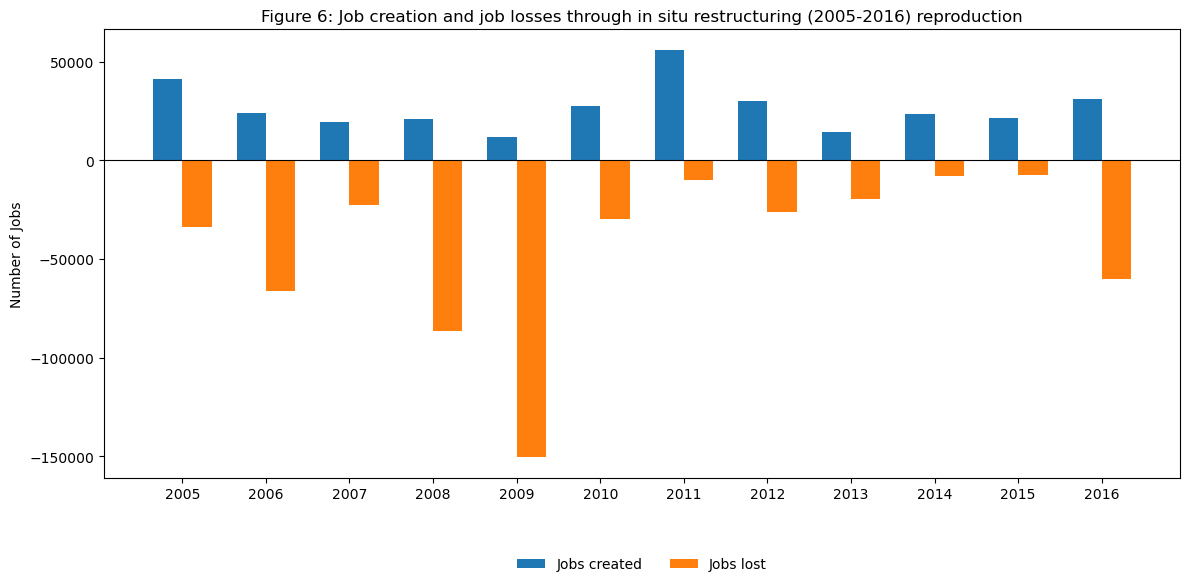

In [31]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# 1. Load and prepare the dataset
# df = pd.read_csv("17_04_2026_ERM.xlsx - 17_04_2026_ERM.csv")
df['d_date_announcement'] = pd.to_datetime(df['d_date_announcement'], format='%Y-%m-%d', errors='coerce')
df['year'] = df['d_date_announcement'].dt.year
df_period = df[(df['year'] >= 2005) & (df['year'] <= 2016)].copy()

# Filter Automotive Industry (NACE 29)
df_auto = df_period[df_period['NACE_level_3'].astype(str).str.contains('^29', regex=True, na=False) | 
                    df_period['NACE_level_4'].astype(str).str.contains('^29', regex=True, na=False)].copy()

# -------------------------------------------------------------
# Data Preparation: In Situ Job Creations
# -------------------------------------------------------------
# Get all expansions >= 100 jobs
df_exp = df_auto[(df_auto['_kf_Type'] == 'Business expansion') & (df_auto['planned job creation'] >= 100)].copy()

# Filter OUT "new factories" using our keyword logic
keywords = ['new factory', 'new plant', 'new facility', 'opens', 'opened', 'new site', 'building a new', 'construct']
pattern = '|'.join(keywords)
df_exp['is_new_factory'] = df_exp['Description'].astype(str).str.lower().str.contains(pattern, regex=True)

# In situ = Expansions that are NOT new factories
df_in_situ_creation = df_exp[df_exp['is_new_factory'] == False]

# Group by year
creation_by_year = df_in_situ_creation.groupby('year')['planned job creation'].sum()

# -------------------------------------------------------------
# Data Preparation: In Situ Job Losses
# -------------------------------------------------------------
# Rule: Average min/max ranges
df_auto['Job_Loss_Avg'] = df_auto[['Planned job red min', 'Planned job red max']].mean(axis=1)
df_auto['Job_Loss_Avg'] = df_auto['Job_Loss_Avg'].fillna(df_auto['Direct dimissals'])

# Isolate 'Internal restructuring' >= 100 jobs
df_in_situ_loss = df_auto[(df_auto['_kf_Type'] == 'Internal restructuring') & (df_auto['Job_Loss_Avg'] >= 100)]

# Group by year (we multiply by -1 to plot the losses below the x-axis like the paper does)
loss_by_year = df_in_situ_loss.groupby('year')['Job_Loss_Avg'].sum() * -1

# Combine into a single DataFrame
fig6_df = pd.DataFrame({
    'Jobs created': creation_by_year,
    'Jobs lost': loss_by_year
}).fillna(0)

# Ensure all years from 2005 to 2016 are present
all_years = pd.Series(index=np.arange(2005, 2017), dtype=float)
fig6_df = fig6_df.reindex(all_years.index).fillna(0)

# -------------------------------------------------------------
# PLOTTING FIGURE 6
# -------------------------------------------------------------
fig, ax = plt.subplots(figsize=(12, 6))

x = np.arange(len(fig6_df.index))
width = 0.35

# Black bars for creation, white bars with black edge for losses (matching the paper's style)
ax.bar(x - width/2, fig6_df['Jobs created'], width, label='Jobs created', color='tab:blue')
ax.bar(x + width/2, fig6_df['Jobs lost'], width, label='Jobs lost', color='tab:orange')

# Formatting to match the author's visual layout
ax.set_xticks(x)
ax.set_xticklabels(fig6_df.index.astype(int))
ax.axhline(0, color='black', linewidth=0.8) # 0-line to separate positive/negative
ax.set_ylabel('Number of Jobs')

# Move legend to the bottom center
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=2, frameon=False)

plt.title("Figure 6: Job creation and job losses through in situ restructuring (2005-2016) reproduction")
plt.tight_layout()
plt.savefig("figure_6_reproduced.png", bbox_inches='tight')
plt.show()